=== PRAKTIKUM 1: MENENTUKAN K OPTIMAL (ELBOW & SILHOUETTE) ===
k= 2 : Inertia=515.37, Silhouette Score=0.584
k= 3 : Inertia=102.86, Silhouette Score=0.786
k= 4 : Inertia=10.60, Silhouette Score=0.880
k= 5 : Inertia=9.43, Silhouette Score=0.743
k= 6 : Inertia=8.42, Silhouette Score=0.604
k= 7 : Inertia=7.46, Silhouette Score=0.475
k= 8 : Inertia=6.59, Silhouette Score=0.349
k= 9 : Inertia=6.15, Silhouette Score=0.341
k=10 : Inertia=5.48, Silhouette Score=0.354


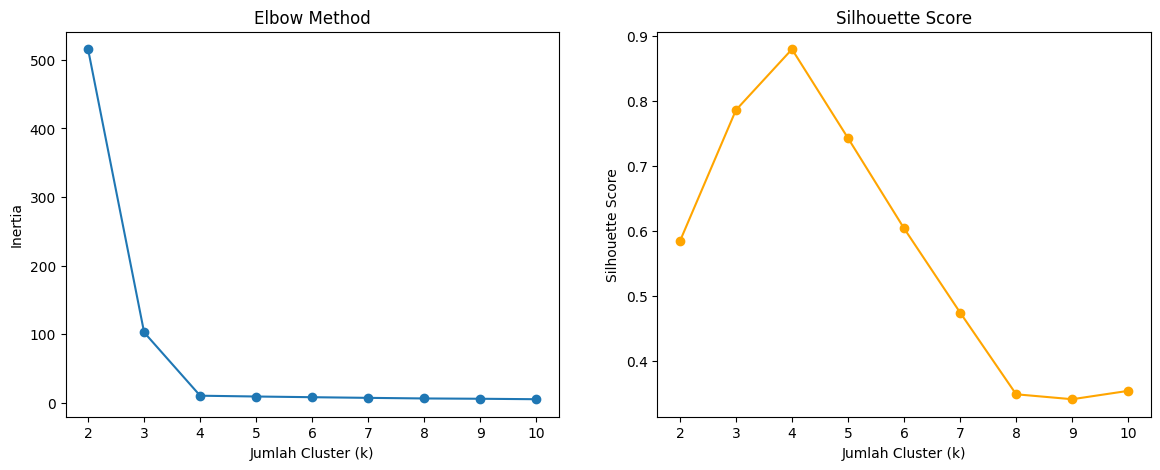


=== PRAKTIKUM 2: SEGMENTASI DENGAN TIGA ALGORITMA ===


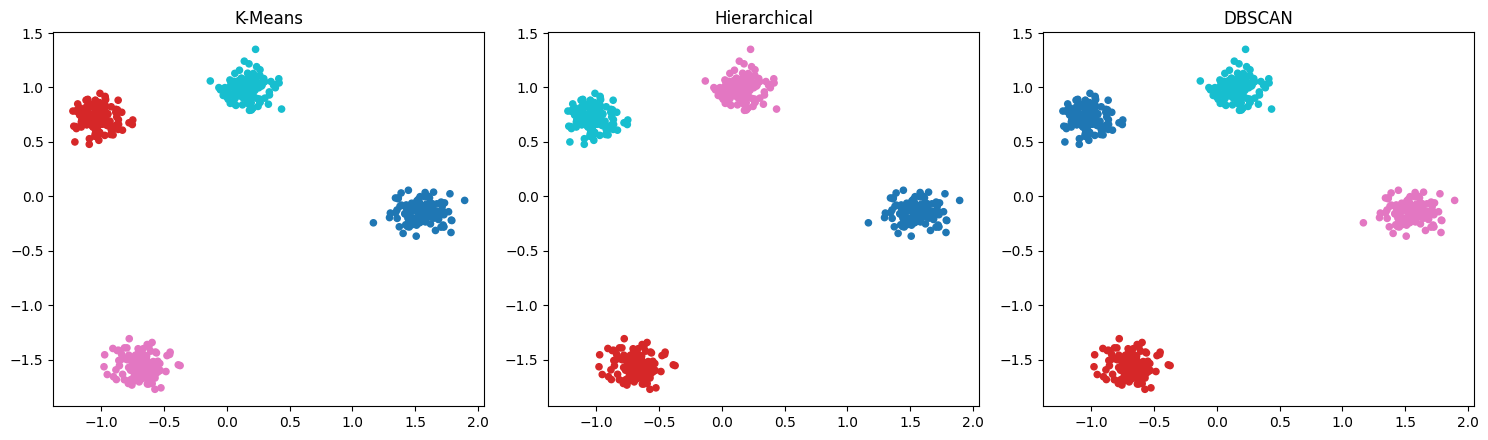

In [4]:
# ==========================================
# PRAKTIKUM BAB 10: CLUSTERING (K-MEANS, HIERARCHICAL, DBSCAN)
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

# 1. Buat dataset sintetis untuk clustering
X, _ = make_blobs(n_samples=500, centers=4, cluster_std=0.60, random_state=42)

# StandardScaler wajib untuk clustering agar jarak antar fitur adil
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("=== PRAKTIKUM 1: MENENTUKAN K OPTIMAL (ELBOW & SILHOUETTE) ===")
inertia = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

    # Hitung Silhouette Score
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)
    print(f"k={k:2} : Inertia={kmeans.inertia_:.2f}, Silhouette Score={score:.3f}")

# Plot Elbow Method & Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertia, marker='o')
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Jumlah Cluster (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(K_range, silhouette_scores, marker='o', color='orange')
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Jumlah Cluster (k)")
axes[1].set_ylabel("Silhouette Score")
plt.show()


print("\n=== PRAKTIKUM 2: SEGMENTASI DENGAN TIGA ALGORITMA ===")
# Terapkan 3 algoritma dengan k optimal = 4 (berdasarkan simulasi data blob)
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_scaled)
agg_model = AgglomerativeClustering(n_clusters=4).fit(X_scaled)
dbscan_model = DBSCAN(eps=0.3, min_samples=5).fit(X_scaled)

labels_kmeans = kmeans_model.labels_
labels_agg = agg_model.labels_
labels_dbscan = dbscan_model.labels_

# Visualisasi perbandingan dalam 1 figure berdampingan (subplot)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, labels, judul in zip(axes, [labels_kmeans, labels_agg, labels_dbscan], ["K-Means", "Hierarchical", "DBSCAN"]):
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap="tab10", s=20)
    ax.set_title(judul)

plt.tight_layout()
plt.show()